In [1]:
# %pip install "sympy<1.13"
# %pip install -U scikit-learn

In [2]:
import pandas as pd

In [3]:
# Run this cell if your CSV file is in Google Drive
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [4]:
# Set the path to the directory containing the csv files
csv_location = '/content/drive/MyDrive/ML Project/Dataset/'

In [5]:
# Load the csv files
films_df = pd.read_csv(csv_location + "films_2012_to_2023.csv")
nominees_df = pd.read_csv(csv_location + "nominees_2012_to_2023.csv")

# Combine
films_df['is_nominee'] = films_df['title'].isin(nominees_df['film'])

In [6]:
films_df

,rank,title,worldwide_revenue,domestic_revenue,domestic_percent,foreign_revenue,foreign_percent,year,genres,is_action,...,is_war,is_western,rating,vote_count,original_language,production_countries,director,duration,is_winner,is_nominee
0,52,Paranormal Activity 4,142802657,53885000,37.7,88917657,62.3,2012,Horror,0,...,0,0,5.41,1875,en,United Kingdom,Henry Joost,88,False,False
1,53,Step Up Revolution,140470746,35074677,25.0,105396069,75.0,2012,"Music, Drama, Romance",0,...,0,0,6.90,2037,en,United Kingdom,Scott Speer,99,False,False
2,54,The Best Exotic Marigold Hotel,136836156,46412041,33.9,90424115,66.1,2012,"Drama, Comedy",0,...,0,0,6.95,1334,en,United Kingdom,John Madden,124,False,False
3,57,Zero Dark Thirty,132820716,95720716,72.1,37100000,27.9,2012,"Thriller, Drama",0,...,0,0,6.99,4505,en,United Kingdom,Kathryn Bigelow,157,False,True
4,58,Ghost Rider: Spirit of Vengeance,132563930,51774002,39.1,80789928,60.9,2012,"Action, Fantasy, Thriller",1,...,0,0,5.01,3782,en,United Kingdom,Mark Neveldine,95,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1512,14,Slumdog Millionaire,378410113,141319928,37.3,237090185,62.7,2008,"Drama, Romance",0,...,0,0,7.73,10573,en,USA,Danny Boyle,120,True,False
1513,105,The Hurt Locker,49230772,17017811,34.6,32212961,65.4,2008,"Drama, Thriller, War",0,...,1,0,7.26,5617,en,USA,Kathryn Bigelow,130,True,False
1514,13,The King's Speech,412018551,135453143,32.9,276565408,67.1,2010,"Drama, History",0,...,0,0,7.70,8701,en,United Kingdom,Tom Hooper,119,True,False
1515,36,Argo,232325503,136025503,58.5,96300000,41.5,2012,"Drama, Thriller",0,...,0,0,7.30,8269,en,USA,Ben Affleck,120,True,True


# **Preprocessing Steps**



## 0.   Feature Selection





In [7]:
TARGET_COLUMN = "is_nominee"
drop_columns = [TARGET_COLUMN, 'genres', 'title', 'year']

X = films_df.drop(columns=drop_columns)
y = films_df[TARGET_COLUMN]

## 1. Encoding

In [8]:
import numpy as np
from sklearn.preprocessing import LabelEncoder
from sklearn.feature_extraction.text import CountVectorizer

# Categorical encoding
le = LabelEncoder()
y = np.array(le.fit_transform(y))

X['original_language'] = le.fit_transform(X['original_language'])
X['production_countries'] = le.fit_transform(X['production_countries'])
X['director'] = le.fit_transform(X['director'])
X['is_winner'] = le.fit_transform(X['is_winner'])


## 2. Split Data

In [9]:
from sklearn.model_selection import train_test_split

# Split into train and test set
X_train, X_test, y_train, y_test = train_test_split(X,y, test_size=0.2, random_state=42, stratify=y)

## 3. Handle Class Imbalance

In [53]:
from collections import Counter
from imblearn.under_sampling import RandomUnderSampler
from imblearn.over_sampling import SMOTE
from sklearn.utils.class_weight import compute_class_weight
from imblearn.pipeline import Pipeline

pipeline = Pipeline([
    ("smote", SMOTE(random_state=42)),
    ("rus", RandomUnderSampler(random_state=42))])

## 4. Scale Features

In [54]:
from sklearn.preprocessing import StandardScaler

pipeline.steps.append(("scaler", StandardScaler()))

# **Building the MLP**

In [55]:
from sklearn.neural_network import MLPClassifier

mlp = MLPClassifier(solver='adam',
                    max_iter=500,
                    early_stopping=True,
                    validation_fraction=0.2,
                    random_state=42)
pipeline.steps.append(("mlp", mlp))

### Hyperparameter Tuning

In [56]:
from sklearn.model_selection import TunedThresholdClassifierCV, GridSearchCV
from sklearn.utils.class_weight import compute_sample_weight


parameter_space = {
    'smote__sampling_strategy': [1/3, 1/2, 2/3],
    'rus__sampling_strategy': [0.6, 0.7, 0.8, 0.9],
    'mlp__hidden_layer_sizes': [(16,), (32,), (64,)],
    'mlp__alpha': [0.0001, 0.001, 0.01],
    'mlp__batch_size': [32, 64, 128],
}

grid_search = GridSearchCV(
    estimator=pipeline,
    param_grid=parameter_space,
    scoring="roc_auc",
    n_jobs=1,
    verbose=2,
)

tuned_model = TunedThresholdClassifierCV(
    estimator=grid_search,
    thresholds=[0.4, 0.5, 0.6, 0.7, 0.75, 0.8],
    scoring='f1_macro',
    random_state=42,
)

tuned_model.fit(X_train, y_train)

Fitting 5 folds for each of 324 candidates, totalling 1620 fits
[CV] END mlp__alpha=0.0001, mlp__batch_size=32, mlp__hidden_layer_sizes=(16,), rus__sampling_strategy=0.6, smote__sampling_strategy=0.3333333333333333; total time=   0.2s
[CV] END mlp__alpha=0.0001, mlp__batch_size=32, mlp__hidden_layer_sizes=(16,), rus__sampling_strategy=0.6, smote__sampling_strategy=0.3333333333333333; total time=   0.2s
[CV] END mlp__alpha=0.0001, mlp__batch_size=32, mlp__hidden_layer_sizes=(16,), rus__sampling_strategy=0.6, smote__sampling_strategy=0.3333333333333333; total time=   0.2s
[CV] END mlp__alpha=0.0001, mlp__batch_size=32, mlp__hidden_layer_sizes=(16,), rus__sampling_strategy=0.6, smote__sampling_strategy=0.3333333333333333; total time=   0.2s
[CV] END mlp__alpha=0.0001, mlp__batch_size=32, mlp__hidden_layer_sizes=(16,), rus__sampling_strategy=0.6, smote__sampling_strategy=0.3333333333333333; total time=   0.2s
[CV] END mlp__alpha=0.0001, mlp__batch_size=32, mlp__hidden_layer_sizes=(16,), ru

/usr/local/lib/python3.13/dist-packages/sklearn/model_selection/_validation.py:528: FitFailedWarning: 
135 fits failed out of a total of 1620.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
135 fits failed with the following error:
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/sklearn/model_selection/_validation.py", line 866, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
    ~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.13/dist-packages/sklearn/base.py", line 1389, in wrapper
    return fit_method(estimator, *args, **kwargs)
  File "/usr/local/lib/python3.13/dist-packages/imblearn/pipeline.py", line 514, in fit
    Xt, yt = self._fit(X, y, routed_

Fitting 5 folds for each of 324 candidates, totalling 1620 fits
[CV] END mlp__alpha=0.0001, mlp__batch_size=32, mlp__hidden_layer_sizes=(16,), rus__sampling_strategy=0.6, smote__sampling_strategy=0.3333333333333333; total time=   0.2s
[CV] END mlp__alpha=0.0001, mlp__batch_size=32, mlp__hidden_layer_sizes=(16,), rus__sampling_strategy=0.6, smote__sampling_strategy=0.3333333333333333; total time=   0.2s
[CV] END mlp__alpha=0.0001, mlp__batch_size=32, mlp__hidden_layer_sizes=(16,), rus__sampling_strategy=0.6, smote__sampling_strategy=0.3333333333333333; total time=   0.1s
[CV] END mlp__alpha=0.0001, mlp__batch_size=32, mlp__hidden_layer_sizes=(16,), rus__sampling_strategy=0.6, smote__sampling_strategy=0.3333333333333333; total time=   0.1s
[CV] END mlp__alpha=0.0001, mlp__batch_size=32, mlp__hidden_layer_sizes=(16,), rus__sampling_strategy=0.6, smote__sampling_strategy=0.3333333333333333; total time=   0.2s
[CV] END mlp__alpha=0.0001, mlp__batch_size=32, mlp__hidden_layer_sizes=(16,), ru

/usr/local/lib/python3.13/dist-packages/sklearn/model_selection/_validation.py:528: FitFailedWarning: 
135 fits failed out of a total of 1620.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
135 fits failed with the following error:
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/sklearn/model_selection/_validation.py", line 866, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
    ~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.13/dist-packages/sklearn/base.py", line 1389, in wrapper
    return fit_method(estimator, *args, **kwargs)
  File "/usr/local/lib/python3.13/dist-packages/imblearn/pipeline.py", line 514, in fit
    Xt, yt = self._fit(X, y, routed_

[CV] END mlp__alpha=0.0001, mlp__batch_size=32, mlp__hidden_layer_sizes=(16,), rus__sampling_strategy=0.6, smote__sampling_strategy=0.3333333333333333; total time=   0.1s
[CV] END mlp__alpha=0.0001, mlp__batch_size=32, mlp__hidden_layer_sizes=(16,), rus__sampling_strategy=0.6, smote__sampling_strategy=0.3333333333333333; total time=   0.2s
[CV] END mlp__alpha=0.0001, mlp__batch_size=32, mlp__hidden_layer_sizes=(16,), rus__sampling_strategy=0.6, smote__sampling_strategy=0.3333333333333333; total time=   0.1s
[CV] END mlp__alpha=0.0001, mlp__batch_size=32, mlp__hidden_layer_sizes=(16,), rus__sampling_strategy=0.6, smote__sampling_strategy=0.3333333333333333; total time=   0.1s
[CV] END mlp__alpha=0.0001, mlp__batch_size=32, mlp__hidden_layer_sizes=(16,), rus__sampling_strategy=0.6, smote__sampling_strategy=0.3333333333333333; total time=   0.2s
[CV] END mlp__alpha=0.0001, mlp__batch_size=32, mlp__hidden_layer_sizes=(16,), rus__sampling_strategy=0.6, smote__sampling_strategy=0.5; total ti

/usr/local/lib/python3.13/dist-packages/sklearn/model_selection/_validation.py:528: FitFailedWarning: 
135 fits failed out of a total of 1620.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
135 fits failed with the following error:
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/sklearn/model_selection/_validation.py", line 866, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
    ~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.13/dist-packages/sklearn/base.py", line 1389, in wrapper
    return fit_method(estimator, *args, **kwargs)
  File "/usr/local/lib/python3.13/dist-packages/imblearn/pipeline.py", line 514, in fit
    Xt, yt = self._fit(X, y, routed_

... (3 outputs left out)

/usr/local/lib/python3.13/dist-packages/sklearn/model_selection/_validation.py:528: FitFailedWarning: 
135 fits failed out of a total of 1620.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
135 fits failed with the following error:
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/sklearn/model_selection/_validation.py", line 866, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
    ~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.13/dist-packages/sklearn/base.py", line 1389, in wrapper
    return fit_method(estimator, *args, **kwargs)
  File "/usr/local/lib/python3.13/dist-packages/imblearn/pipeline.py", line 514, in fit
    Xt, yt = self._fit(X, y, routed_

Fitting 5 folds for each of 324 candidates, totalling 1620 fits
[CV] END mlp__alpha=0.0001, mlp__batch_size=32, mlp__hidden_layer_sizes=(16,), rus__sampling_strategy=0.6, smote__sampling_strategy=0.3333333333333333; total time=   0.3s
[CV] END mlp__alpha=0.0001, mlp__batch_size=32, mlp__hidden_layer_sizes=(16,), rus__sampling_strategy=0.6, smote__sampling_strategy=0.3333333333333333; total time=   0.2s
[CV] END mlp__alpha=0.0001, mlp__batch_size=32, mlp__hidden_layer_sizes=(16,), rus__sampling_strategy=0.6, smote__sampling_strategy=0.3333333333333333; total time=   0.3s
[CV] END mlp__alpha=0.0001, mlp__batch_size=32, mlp__hidden_layer_sizes=(16,), rus__sampling_strategy=0.6, smote__sampling_strategy=0.3333333333333333; total time=   0.1s
[CV] END mlp__alpha=0.0001, mlp__batch_size=32, mlp__hidden_layer_sizes=(16,), rus__sampling_strategy=0.6, smote__sampling_strategy=0.3333333333333333; total time=   0.1s
[CV] END mlp__alpha=0.0001, mlp__batch_size=32, mlp__hidden_layer_sizes=(16,), ru

/usr/local/lib/python3.13/dist-packages/sklearn/model_selection/_validation.py:528: FitFailedWarning: 
135 fits failed out of a total of 1620.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
135 fits failed with the following error:
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/sklearn/model_selection/_validation.py", line 866, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
    ~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.13/dist-packages/sklearn/base.py", line 1389, in wrapper
    return fit_method(estimator, *args, **kwargs)
  File "/usr/local/lib/python3.13/dist-packages/imblearn/pipeline.py", line 514, in fit
    Xt, yt = self._fit(X, y, routed_

TunedThresholdClassifierCV(estimator=GridSearchCV(estimator=Pipeline(steps=[('smote',
                                                                             SMOTE(random_state=42)),
                                                                            ('rus',
                                                                             RandomUnderSampler(random_state=42)),
                                                                            ('scaler',
                                                                             StandardScaler()),
                                                                            ('mlp',
                                                                             MLPClassifier(early_stopping=True,
                                                                                           max_iter=500,
                                                                                           random_state=42,
                                                                                           validation_fraction=0.2))]),
                                                  n_jobs=1,
                                                  param_grid={'mlp__alpha': [0.0001,
                                                                             0.001,
                                                                             0.01],
                                                              'mlp__batch_size': [32,
                                                                                  64,
                                                                                  128],
                                                              'mlp__hidden_layer_sizes': [(16,),
                                                                                          (32,),
                                                                                          (64,)],
                                                              'rus__sampling_strategy': [0.6,
                                                                                         0.7,
                                                                                         0.8,
                                                                                         0.9],
                                                              'smote__sampling_strategy': [0.3333333333333333,
                                                                                           0.5,
                                                                                           0.6666666666666666]},
                                                  scoring='roc_auc',
                                                  verbose=2),
                           random_state=42, scoring='f1_macro',
                           thresholds=[0.4, 0.5, 0.6, 0.7, 0.75, 0.8])

In [57]:
print(f"Best threshold: {tuned_model.best_threshold_}")
print(f"Best parameters: {tuned_model.estimator_.best_params_}")

Best threshold: 0.6
Best parameters: {'mlp__alpha': 0.0001, 'mlp__batch_size': 32, 'mlp__hidden_layer_sizes': (64,), 'rus__sampling_strategy': 0.8, 'smote__sampling_strategy': 0.3333333333333333}


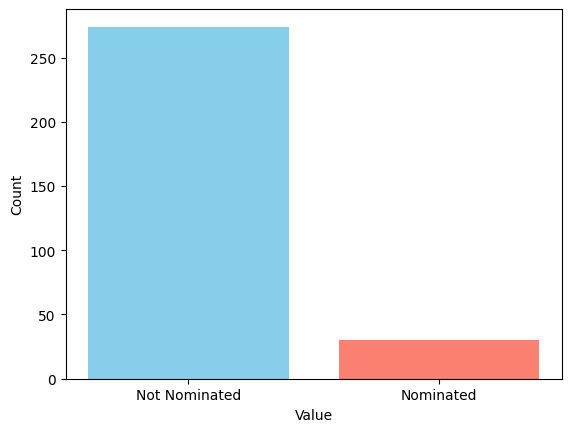

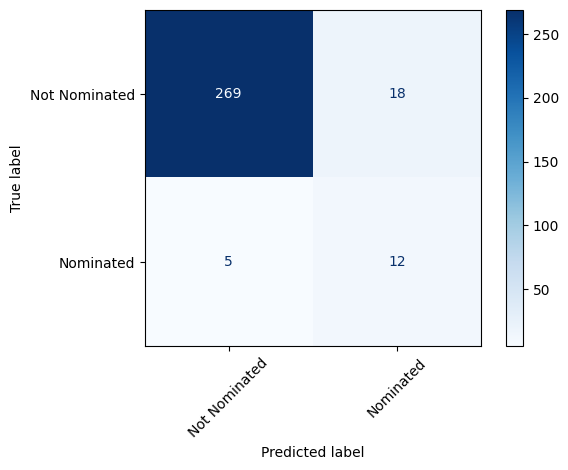

               precision    recall  f1-score   support

Not Nominated       0.98      0.94      0.96       287
    Nominated       0.40      0.71      0.51        17

     accuracy                           0.92       304
    macro avg       0.69      0.82      0.73       304
 weighted avg       0.95      0.92      0.93       304



In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay, classification_report
import matplotlib.pyplot as plt

y_pred = tuned_model.predict(X_test)
classes, counts = np.unique(y_pred, return_counts=True)

plt.bar(['Not Nominated', 'Nominated'], counts, color=['skyblue', 'salmon'])
plt.xlabel('Value')
plt.ylabel('Count')
plt.show()

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred,
    display_labels=['Not Nominated', 'Nominated'],
    xticks_rotation=45, cmap="Blues", values_format="d"
)
plt.tight_layout()
plt.show()

print(classification_report(y_test, y_pred, target_names=['Not Nominated', 'Nominated'], zero_division=0))
